# Phase 2 - Notebook 4: IA Preentrenada (Chronos) para extraer segmentos 2017-2019

Este notebook usa una IA ya creada (**Chronos-2**, modelo foundation de series temporales) para detectar puntos de interes en USDJPY y convertirlos en segmentos entre **2017-01-01** y **2019-12-31**.

Pipeline:
1. Carga H1 y filtra 2017-2019.
2. Infiere rolling forecasts con Chronos.
3. Construye score de evento (error + incertidumbre).
4. Agrupa eventos en segmentos y clasifica patron dominante.
5. Exporta resultados a `parquet/csv`.


In [1]:
# Si hace falta, descomenta para instalar dependencias:
# %pip install -q "chronos-forecasting>=1.5.0" "torch>=2.2" "pandas[pyarrow]" matplotlib tqdm


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 240)


In [3]:
# =========================
# Config
# =========================
SYMBOL = 'USDJPY'

# Usa por defecto el dataset H1 amplio detectado en tu maquina
DATA_PATH = Path('./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet')

START_TS = pd.Timestamp('2017-01-01 00:00:00')
END_TS = pd.Timestamp('2019-12-31 23:59:59')

# Modelo IA preentrenado
MODEL_ID = 'amazon/chronos-2'  # Alternativa liviana: amazon/chronos-bolt-mini

# Rolling inference
CONTEXT_BARS = 256
PREDICTION_LENGTH = 8
ROLL_STEP = 24
QUANTILES = [0.1, 0.5, 0.9]

# Segmentacion
MIN_SCORE_Z = 2.2
EVENT_QUANTILE = 0.90
EVENT_MAX_GAP_BARS = 12
SEG_PREPAD = 6
SEG_POSTPAD = 10
MIN_SEG_BARS = 8
MAX_SEG_BARS = 160

# Salida
OUTPUT_DIR = Path('./phases/phase02_market_alphabet/output_segments_ai_2017_2019')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SIGNALS_PARQUET = OUTPUT_DIR / f'{SYMBOL}_chronos_signals_2017_2019.parquet'
SIGNALS_CSV = OUTPUT_DIR / f'{SYMBOL}_chronos_signals_2017_2019.csv'
SEGMENTS_PARQUET = OUTPUT_DIR / f'{SYMBOL}_chronos_segments_2017_2019.parquet'
SEGMENTS_CSV = OUTPUT_DIR / f'{SYMBOL}_chronos_segments_2017_2019.csv'

print('DATA_PATH =', DATA_PATH)
print('OUTPUT_DIR =', OUTPUT_DIR)


DATA_PATH = ./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet
OUTPUT_DIR = ./phases/phase02_market_alphabet/output_segments_ai_2017_2019


In [4]:
# =========================
# Helpers
# =========================
def pip_size(symbol: str) -> float:
    return 0.01 if symbol.upper().endswith('JPY') else 0.0001


def robust_zscore(x: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if mad < 1e-9:
        std = np.nanstd(x)
        if std < 1e-9:
            return np.zeros_like(x, dtype=float)
        z = (x - np.nanmean(x)) / (std + eps)
    else:
        z = (x - med) / (1.4826 * mad + eps)
    return np.clip(z, -8.0, 8.0)


def load_ohlc(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f'No existe DATA_PATH: {path}')

    df = pd.read_parquet(path).copy()
    required = ['timestamp', 'open', 'high', 'low', 'close']
    miss = [c for c in required if c not in df.columns]
    if miss:
        raise ValueError(f'Faltan columnas {miss} en {path}')

    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    for c in ['open', 'high', 'low', 'close']:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    df = df.dropna(subset=['timestamp', 'close'])
    df = df.sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)
    return df


def guess_prediction_column(pred_df: pd.DataFrame) -> str:
    if 'predictions' in pred_df.columns:
        return 'predictions'
    for c in ['0.5', 'median', 'mean']:
        if c in pred_df.columns:
            return c
    num_cols = [c for c in pred_df.columns if pd.api.types.is_numeric_dtype(pred_df[c])]
    protected = {'0.1', '0.9'}
    num_cols = [c for c in num_cols if c not in protected]
    if not num_cols:
        raise ValueError(f'No encontre columna de prediccion en: {list(pred_df.columns)}')
    return num_cols[0]


def classify_event(actual: float, q_low: float, q_high: float, score: float, threshold: float) -> str:
    if np.isfinite(q_high) and actual > q_high:
        return 'bullish_breakout'
    if np.isfinite(q_low) and actual < q_low:
        return 'bearish_breakout'
    if score >= threshold:
        return 'regime_shift'
    return 'normal'


def classify_segment(row: pd.Series) -> str:
    move_pips = float(row['net_move_pips'])
    range_pips = float(row['range_pips'])
    dominant = str(row['dominant_event'])

    if dominant == 'bullish_breakout' and move_pips > 0:
        return 'bullish_impulse'
    if dominant == 'bearish_breakout' and move_pips < 0:
        return 'bearish_impulse'
    if range_pips >= 60 and abs(move_pips) <= 0.25 * max(range_pips, 1e-9):
        return 'volatile_range'
    return 'regime_shift'


In [5]:
# =========================
# Carga y filtro 2017-2019
# =========================
DF_ALL = load_ohlc(DATA_PATH)
DF = DF_ALL[(DF_ALL['timestamp'] >= START_TS) & (DF_ALL['timestamp'] <= END_TS)].copy().reset_index(drop=True)

if DF.empty:
    raise ValueError(
        f'No hay datos en [{START_TS} - {END_TS}] en {DATA_PATH}.\n'
        'Genera/copia un parquet H1 que incluya 2017-2019 y vuelve a ejecutar.'
    )

DF['idx'] = np.arange(len(DF), dtype=int)

print(f'total rows (archivo): {len(DF_ALL):,}')
print(f'rows 2017-2019: {len(DF):,}')
print(f'rango activo: {DF.timestamp.min()} -> {DF.timestamp.max()}')
display(DF.head(3))
display(DF.tail(3))


total rows (archivo): 155,465
rows 2017-2019: 18,653
rango activo: 2017-01-02 02:00:00 -> 2019-12-31 16:00:00


,timestamp,open,high,low,close,volume,n_m1,is_complete,gap_hours,is_gap,is_weekend_gap,is_data_gap,idx
0,2017-01-02 02:00:00,116.858002,117.144997,116.858002,117.124001,0.0,56,False,58,True,False,True,0
1,2017-01-02 03:00:00,117.124001,117.445999,117.108002,117.373001,0.0,58,False,1,False,False,False,1
2,2017-01-02 04:00:00,117.373001,117.435997,117.292000,117.412003,0.0,58,False,1,False,False,False,2


,timestamp,open,high,low,close,volume,n_m1,is_complete,gap_hours,is_gap,is_weekend_gap,is_data_gap,idx
18650,2019-12-31 14:00:00,108.620003,108.639999,108.609001,108.636002,0.0,58,False,1,False,False,False,18650
18651,2019-12-31 15:00:00,108.638000,108.665001,108.629997,108.663002,0.0,60,True,1,False,False,False,18651
18652,2019-12-31 16:00:00,108.661003,108.675003,108.619003,108.619003,0.0,54,False,1,False,False,False,18652


In [6]:
# =========================
# Cargar IA preentrenada (Chronos)
# =========================
import torch
from chronos import Chronos2Pipeline

DEVICE_MAP = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch.cuda.is_available =', torch.cuda.is_available())
print('DEVICE_MAP =', DEVICE_MAP)
print('MODEL_ID =', MODEL_ID)

pipeline = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map=DEVICE_MAP)
print('Modelo cargado')


torch.cuda.is_available = True
DEVICE_MAP = cuda
MODEL_ID = amazon/chronos-2


Modelo cargado


In [7]:
# =========================
# Rolling inference -> señales
# =========================
from tqdm.auto import tqdm

pip = pip_size(SYMBOL)
actual_map = DF.set_index('timestamp')['close']

rows = []
origins = range(CONTEXT_BARS, len(DF) - PREDICTION_LENGTH, ROLL_STEP)

for origin in tqdm(origins, desc='Chronos rolling'):
    ctx_start = max(0, origin - CONTEXT_BARS)
    ctx_raw = DF.iloc[ctx_start:origin][['timestamp', 'close']].copy()
    if len(ctx_raw) < 32:
        continue

    # Chronos requiere timestamps regulares para inferir frecuencia.
    ctx_reg = ctx_raw.set_index('timestamp').sort_index().asfreq('h')
    ctx_reg['close'] = ctx_reg['close'].ffill().bfill()
    ctx_reg = ctx_reg.dropna(subset=['close']).reset_index()
    if len(ctx_reg) < 32:
        continue

    context_df = pd.DataFrame({
        'id': SYMBOL,
        'timestamp': ctx_reg['timestamp'].to_numpy(),
        'target': ctx_reg['close'].to_numpy(dtype=float),
    })

    pred_df = pipeline.predict_df(
        df=context_df,
        prediction_length=PREDICTION_LENGTH,
        quantile_levels=QUANTILES,
        id_column='id',
        timestamp_column='timestamp',
        target='target',
        validate_inputs=False,
    )

    if pred_df is None or len(pred_df) == 0:
        continue

    pred_df = pred_df.sort_values('timestamp').reset_index(drop=True)
    pred_col = guess_prediction_column(pred_df)

    q_low_col = '0.1' if '0.1' in pred_df.columns else None
    q_high_col = '0.9' if '0.9' in pred_df.columns else None

    r = pred_df.iloc[0]
    ts_eval = pd.Timestamp(r['timestamp'])
    if ts_eval not in actual_map.index:
        continue

    actual = float(actual_map.loc[ts_eval])
    pred = float(r[pred_col])
    q_low = float(r[q_low_col]) if q_low_col is not None else np.nan
    q_high = float(r[q_high_col]) if q_high_col is not None else np.nan

    err_pips = (actual - pred) / pip
    abs_err_pips = abs(err_pips)
    interval_pips = (q_high - q_low) / pip if np.isfinite(q_low) and np.isfinite(q_high) else np.nan

    rows.append({
        'symbol': SYMBOL,
        'origin_idx': int(origin),
        'eval_ts': ts_eval,
        'actual': actual,
        'pred': pred,
        'q10': q_low,
        'q90': q_high,
        'err_pips': err_pips,
        'abs_err_pips': abs_err_pips,
        'interval_pips': interval_pips,
    })

signals = pd.DataFrame(rows)
if signals.empty:
    raise RuntimeError('No se generaron señales. Revisa configuracion y datos.')

signals = signals.sort_values('eval_ts').reset_index(drop=True)
signals['err_z'] = robust_zscore(signals['abs_err_pips'].to_numpy())

if signals['interval_pips'].notna().any():
    fill_unc = float(np.nanmedian(signals['interval_pips'].to_numpy()))
    unc_vec = signals['interval_pips'].fillna(fill_unc).to_numpy()
else:
    unc_vec = np.zeros(len(signals), dtype=float)

signals['unc_z'] = robust_zscore(unc_vec)
signals['score'] = 0.75 * signals['err_z'] + 0.25 * signals['unc_z']

dyn_thr = float(np.nanquantile(signals['score'].to_numpy(), EVENT_QUANTILE))
threshold = max(MIN_SCORE_Z, dyn_thr)

signals['event_label'] = [
    classify_event(a, ql, qh, s, threshold)
    for a, ql, qh, s in zip(signals['actual'], signals['q10'], signals['q90'], signals['score'])
]
signals['is_event'] = signals['event_label'] != 'normal'

print(f'señales totales: {len(signals):,}')
print(f'eventos: {int(signals.is_event.sum()):,} | threshold={threshold:.3f}')
display(signals.head(10))
print(signals['event_label'].value_counts(dropna=False).to_string())


Chronos rolling:   0%|          | 0/767 [00:00<?, ?it/s]

señales totales: 767
eventos: 205 | threshold=2.200


,symbol,origin_idx,eval_ts,actual,pred,q10,q90,err_pips,abs_err_pips,interval_pips,err_z,unc_z,score,event_label,is_event
0,USDJPY,256,2017-01-16 18:00:00,114.155998,114.077095,113.920547,114.197128,7.890320,7.890320,27.658081,0.618257,1.198831,0.763400,normal,False
1,USDJPY,280,2017-01-17 18:00:00,112.889999,112.719032,112.414085,113.036568,17.096710,17.096710,62.248230,2.513711,5.504669,3.261451,regime_shift,True
2,USDJPY,304,2017-01-18 18:00:00,114.711998,114.516747,114.258339,114.743584,19.525146,19.525146,48.524475,3.013689,3.796314,3.209345,regime_shift,True
3,USDJPY,328,2017-01-19 18:00:00,114.938004,115.135399,114.958221,115.305595,-19.739532,19.739532,34.737396,3.057828,2.080076,2.813390,bearish_breakout,True
4,USDJPY,352,2017-01-22 18:00:00,113.804001,114.434380,114.299026,114.508049,-63.037872,63.037872,20.902252,8.000000,0.357854,6.089464,bearish_breakout,True
5,USDJPY,376,2017-01-23 18:00:00,112.781998,112.499550,112.095802,112.858925,28.244781,28.244781,76.312256,4.808927,7.255382,5.420541,regime_shift,True
6,USDJPY,400,2017-01-24 18:00:00,113.862000,113.895638,113.703476,114.066544,-3.363800,3.363800,36.306763,-0.313684,2.275433,0.333595,normal,False
7,USDJPY,424,2017-01-25 18:00:00,113.272003,113.320335,113.036880,113.626701,-4.833221,4.833221,58.982086,-0.011153,5.098094,1.266159,normal,False
8,USDJPY,448,2017-01-26 18:00:00,114.418999,114.531204,114.358345,114.715576,-11.220551,11.220551,35.723114,1.303900,2.202779,1.528620,normal,False
9,USDJPY,472,2017-01-29 18:00:00,114.652000,114.885933,114.729576,114.987473,-23.393250,23.393250,25.789642,3.810072,0.966245,3.099115,bearish_breakout,True


event_label
normal              562
bearish_breakout    102
bullish_breakout     91
regime_shift         12


In [8]:
# =========================
# Eventos -> segmentos
# =========================
idx_map = DF.set_index('timestamp')['idx'].to_dict()

event_points = signals.loc[signals['is_event'], ['eval_ts', 'event_label', 'score']].copy()
if event_points.empty:
    raise RuntimeError('No hubo eventos para segmentar. Prueba bajar MIN_SCORE_Z o EVENT_QUANTILE.')

event_points['idx'] = event_points['eval_ts'].map(idx_map)
event_points = event_points.dropna(subset=['idx']).copy()
event_points['idx'] = event_points['idx'].astype(int)
event_points = event_points.sort_values('idx').reset_index(drop=True)

clusters = []
current = [int(event_points.loc[0, 'idx'])]

for i in range(1, len(event_points)):
    idx_i = int(event_points.loc[i, 'idx'])
    if idx_i - current[-1] <= EVENT_MAX_GAP_BARS:
        current.append(idx_i)
    else:
        clusters.append(current)
        current = [idx_i]
clusters.append(current)

segments = []
for c in clusters:
    s = max(0, min(c) - SEG_PREPAD)
    e = min(len(DF) - 1, max(c) + SEG_POSTPAD)
    n = e - s + 1
    if n < MIN_SEG_BARS:
        continue
    if n > MAX_SEG_BARS:
        e = min(len(DF) - 1, s + MAX_SEG_BARS - 1)
        n = e - s + 1

    w = DF.iloc[s:e + 1]
    ev = event_points[(event_points['idx'] >= s) & (event_points['idx'] <= e)]
    dominant_event = ev['event_label'].value_counts().idxmax() if len(ev) else 'regime_shift'

    net_move_pips = (float(w['close'].iloc[-1]) - float(w['close'].iloc[0])) / pip
    range_pips = (float(w['high'].max()) - float(w['low'].min())) / pip
    mean_score = float(ev['score'].mean()) if len(ev) else np.nan
    peak_score = float(ev['score'].max()) if len(ev) else np.nan

    row = {
        'symbol': SYMBOL,
        'start_idx': int(s),
        'end_idx': int(e),
        'start_ts': pd.Timestamp(w['timestamp'].iloc[0]),
        'end_ts': pd.Timestamp(w['timestamp'].iloc[-1]),
        'n_bars': int(n),
        'n_events': int(len(ev)),
        'dominant_event': dominant_event,
        'mean_score': mean_score,
        'peak_score': peak_score,
        'net_move_pips': net_move_pips,
        'range_pips': range_pips,
        'source_model': MODEL_ID,
        'start_price': float(w['close'].iloc[0]),
        'end_price': float(w['close'].iloc[-1]),
    }
    segments.append(row)

SEGMENTS = pd.DataFrame(segments)
if SEGMENTS.empty:
    raise RuntimeError('No se generaron segmentos. Ajusta parametros de segmentacion.')

SEGMENTS = SEGMENTS.sort_values(['peak_score', 'n_events'], ascending=[False, False]).reset_index(drop=True)
SEGMENTS['segment_id'] = [f'{SYMBOL}_2017_2019_{i:04d}' for i in range(len(SEGMENTS))]
SEGMENTS['pattern_type'] = SEGMENTS.apply(classify_segment, axis=1)

# Orden final por tiempo
SEGMENTS = SEGMENTS.sort_values('start_ts').reset_index(drop=True)

print(f'segmentos detectados: {len(SEGMENTS):,}')
display(SEGMENTS.head(20))
print('pattern_type distribution:')
print(SEGMENTS['pattern_type'].value_counts().to_string())


segmentos detectados: 205


,symbol,start_idx,end_idx,start_ts,end_ts,n_bars,n_events,dominant_event,mean_score,peak_score,net_move_pips,range_pips,source_model,start_price,end_price,segment_id,pattern_type
0,USDJPY,274,290,2017-01-17 12:00:00,2017-01-18 04:00:00,17,1,regime_shift,3.261451,3.261451,29.399872,87.099457,amazon/chronos-2,112.932999,113.226997,USDJPY_2017_2019_0027,regime_shift
1,USDJPY,298,314,2017-01-18 12:00:00,2017-01-19 04:00:00,17,1,regime_shift,3.209345,3.209345,113.999939,163.999939,amazon/chronos-2,113.407997,114.547997,USDJPY_2017_2019_0029,regime_shift
2,USDJPY,322,338,2017-01-19 12:00:00,2017-01-20 04:00:00,17,1,bearish_breakout,2.813390,2.813390,-30.899811,108.399963,amazon/chronos-2,115.403999,115.095001,USDJPY_2017_2019_0037,bearish_impulse
3,USDJPY,346,362,2017-01-20 12:00:00,2017-01-23 04:00:00,17,1,bearish_breakout,6.089464,6.089464,-125.500488,202.999878,amazon/chronos-2,114.884003,113.628998,USDJPY_2017_2019_0003,bearish_impulse
4,USDJPY,370,386,2017-01-23 12:00:00,2017-01-24 04:00:00,17,1,regime_shift,5.420541,5.420541,18.499756,91.199493,amazon/chronos-2,113.057999,113.242996,USDJPY_2017_2019_0006,volatile_range
5,USDJPY,466,482,2017-01-27 12:00:00,2017-01-30 04:00:00,17,1,bearish_breakout,3.099115,3.099115,-54.199982,101.399994,amazon/chronos-2,115.223000,114.681000,USDJPY_2017_2019_0031,bearish_impulse
6,USDJPY,586,602,2017-02-03 12:00:00,2017-02-06 04:00:00,17,1,bullish_breakout,0.306308,0.306308,0.500488,84.700012,amazon/chronos-2,112.547997,112.553001,USDJPY_2017_2019_0162,bullish_impulse
7,USDJPY,658,674,2017-02-08 12:00:00,2017-02-09 04:00:00,17,1,bullish_breakout,2.446187,2.446187,47.799683,76.200104,amazon/chronos-2,111.761002,112.238998,USDJPY_2017_2019_0047,bullish_impulse
8,USDJPY,706,722,2017-02-10 12:00:00,2017-02-13 04:00:00,17,1,regime_shift,3.126010,3.126010,45.100403,130.599976,amazon/chronos-2,113.363998,113.815002,USDJPY_2017_2019_0030,regime_shift
9,USDJPY,826,842,2017-02-17 12:00:00,2017-02-20 04:00:00,17,1,bearish_breakout,2.861423,2.861423,28.099823,45.999908,amazon/chronos-2,112.842003,113.123001,USDJPY_2017_2019_0035,regime_shift


pattern_type distribution:
pattern_type
regime_shift       72
bearish_impulse    66
bullish_impulse    60
volatile_range      7


In [9]:
# =========================
# Export
# =========================
signals.to_parquet(SIGNALS_PARQUET, index=False)
signals.to_csv(SIGNALS_CSV, index=False)

SEGMENTS.to_parquet(SEGMENTS_PARQUET, index=False)
SEGMENTS.to_csv(SEGMENTS_CSV, index=False)

print('Guardado OK:')
print(' -', SIGNALS_PARQUET)
print(' -', SIGNALS_CSV)
print(' -', SEGMENTS_PARQUET)
print(' -', SEGMENTS_CSV)


Guardado OK:
 - ./phases/phase02_market_alphabet/output_segments_ai_2017_2019/USDJPY_chronos_signals_2017_2019.parquet
 - ./phases/phase02_market_alphabet/output_segments_ai_2017_2019/USDJPY_chronos_signals_2017_2019.csv
 - ./phases/phase02_market_alphabet/output_segments_ai_2017_2019/USDJPY_chronos_segments_2017_2019.parquet
 - ./phases/phase02_market_alphabet/output_segments_ai_2017_2019/USDJPY_chronos_segments_2017_2019.csv


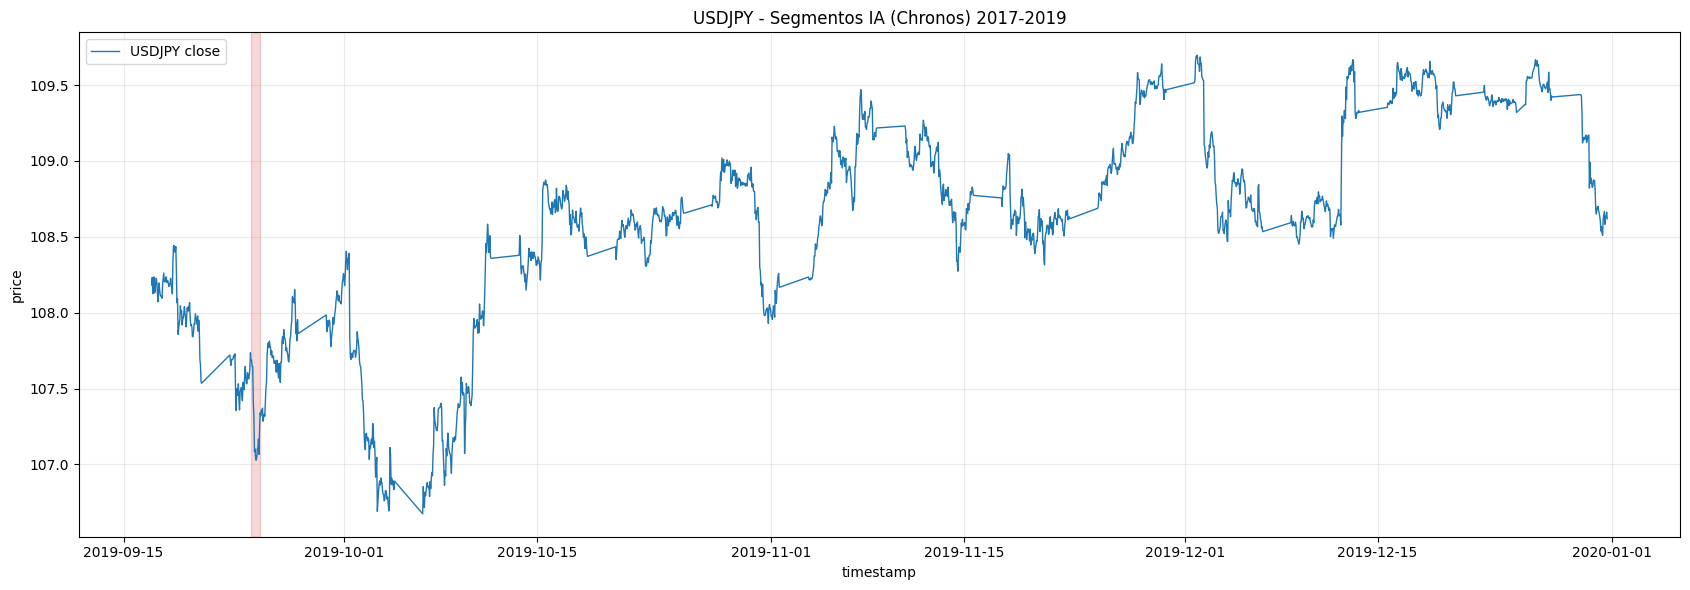

In [10]:
# =========================
# Visual rapido de segmentos top
# =========================
PLOT_LAST_BARS = 1800
PLOT_TOP_SEGMENTS = 25

plot_df = DF.tail(PLOT_LAST_BARS).copy()

fig, ax = plt.subplots(figsize=(17, 6))
ax.plot(plot_df['timestamp'], plot_df['close'], lw=1.0, label=f'{SYMBOL} close')

segments_plot = SEGMENTS.sort_values('peak_score', ascending=False).head(PLOT_TOP_SEGMENTS)
for _, r in segments_plot.iterrows():
    s = pd.Timestamp(r['start_ts'])
    e = pd.Timestamp(r['end_ts'])
    if e < plot_df['timestamp'].iloc[0] or s > plot_df['timestamp'].iloc[-1]:
        continue

    color = {
        'bullish_impulse': '#2ca02c',
        'bearish_impulse': '#d62728',
        'volatile_range': '#ff7f0e',
    }.get(r['pattern_type'], '#1f77b4')

    ax.axvspan(s, e, alpha=0.18, color=color)

ax.set_title(f'{SYMBOL} - Segmentos IA (Chronos) 2017-2019')
ax.set_xlabel('timestamp')
ax.set_ylabel('price')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
